<a href="https://colab.research.google.com/github/Ravikumar-Pawar/hkl-vits-kannada-tts/blob/main/docs/report/hkl_vits_kannada_tts_20260623.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.6/71.6 kB 4.9 MB/s eta 0:00:00
Torch: 2.11.0+cu128
GPU: Tesla T4

========== KANNADA TTS DATASET PIPELINE (Colab) ==========
Base directory: /content
Dataset location: /content/kannada_tts_dataset
WAV folder: /content/kannada_tts_dataset/wavs
Text folder: /content/kannada_tts_dataset/text

Downloading: https://openslr.trmal.net/resources/79/kn_in_male.zip


820404KB [00:42, 19197.48KB/s]                            


Downloaded to: /content/kannada_tts_dataset/dataset.zip

Downloading: https://openslr.trmal.net/resources/79/line_index_male.tsv


387KB [00:00, 653.79KB/s]                         


Downloaded to: /content/kannada_tts_dataset/metadata.tsv

Extracting WAV files...
Extraction completed. WAVs are in /content/kannada_tts_dataset/wavs

Preparing text files...
Text files saved in /content/kannada_tts_dataset/text
Total text files: 2214

========== DATASET READY FOR FINE-TUNING ==========
Total text files: 2214
You can now use this dataset for MMS‑TTS / VITS fine‑tuning.

========== DATASET ANALYSIS ==========
Processing audio files...


100%|██████████| 2214/2214 [00:17<00:00, 129.93it/s]



Dataset Summary
----------------------------------------
Total Samples     : 2214
Total Hours       : 4.17
Average Duration  : 6.79s
Average Text Size : 56.1 chars

Sample Rates
sample_rate
48000    2214
Name: count, dtype: int64


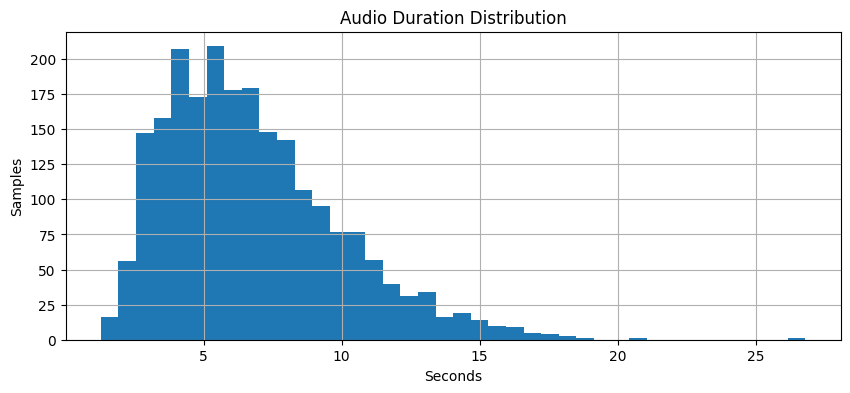

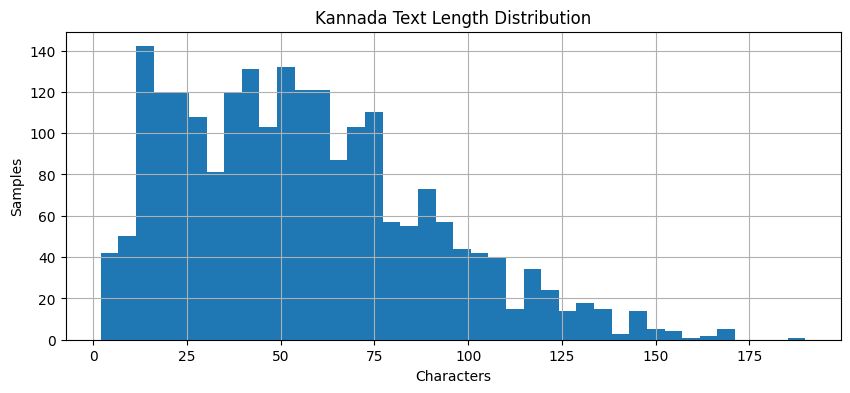


========== AUDIO EXAMPLES ==========

File: knm_06230_00893746998
Text: ಉತ್ಪಾದನೀಯ ಅಂಶಗಳನ್ನು ಆಮದುಮಾಡಿಕೊಳ್ಳುವುದರ ಬದಲು ವಿನಿಮಯ ಮಾಡಿಕೊಳ್ಳಬಹುದು
Duration: 6.83s | Sample Rate: 48000 Hz


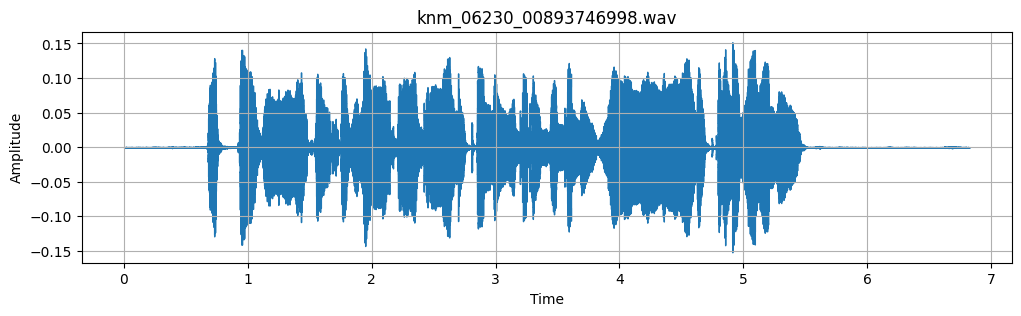


File: knm_09140_01471917557
Text: ಉದಾಹರಣೆಗಾಗಿ
Duration: 3.33s | Sample Rate: 48000 Hz


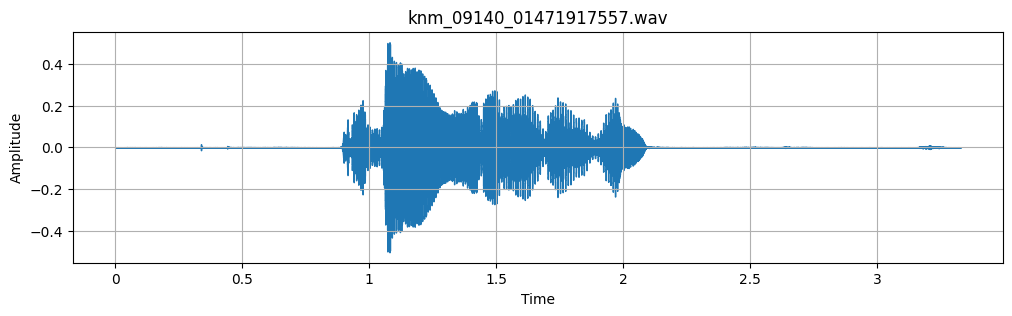


File: knm_05066_00885491945
Text: ಈ ಕೆಲವು ಶಾರೀರಿಕ ಪ್ರತಿಕೂಲ ಪರಿಣಾಮಗಳನ್ನು ತಡೆಗಟ್ಟಲು
Duration: 4.95s | Sample Rate: 48000 Hz


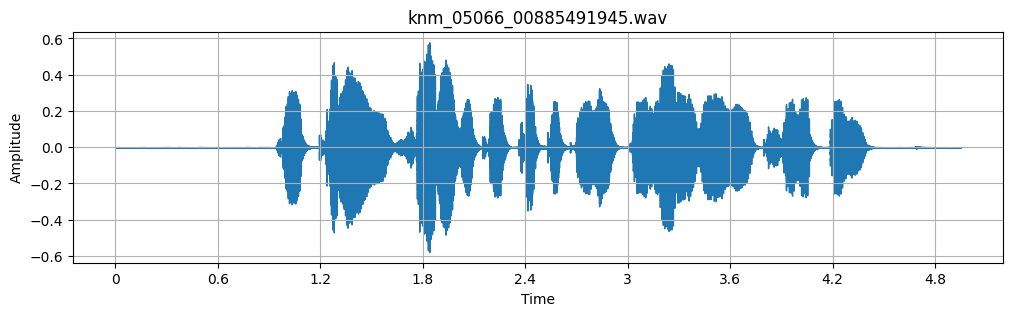


File: knm_06230_01988399728
Text: ಪ್ರಸ್ತುತ ಕಾಗದದ ಎಲೆಯ ಅಲಂಕಾರ ವಿಧಾನವು ಜನಪ್ರಿಯ ಕರಕುಶಲಕಲೆಯಾಗಿದೆ.
Duration: 9.13s | Sample Rate: 48000 Hz


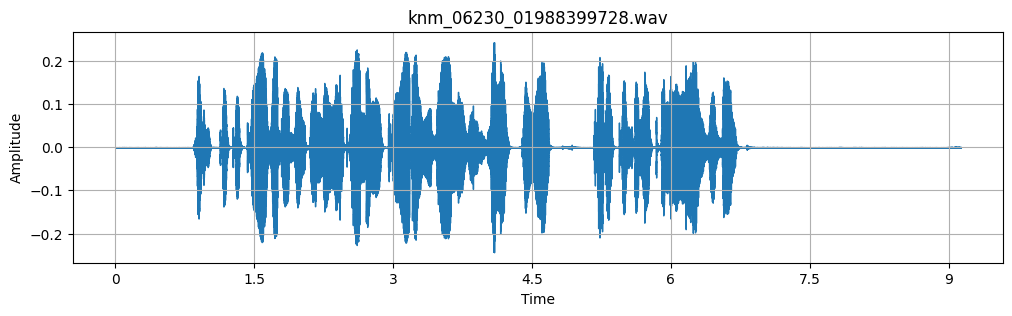


File: knm_00180_01064219273
Text: ಈ ಬರಹವನ್ನು ವಿಸ್ತರಿಸಲು ಸಹಕರಿಸಿ.
Duration: 7.85s | Sample Rate: 48000 Hz


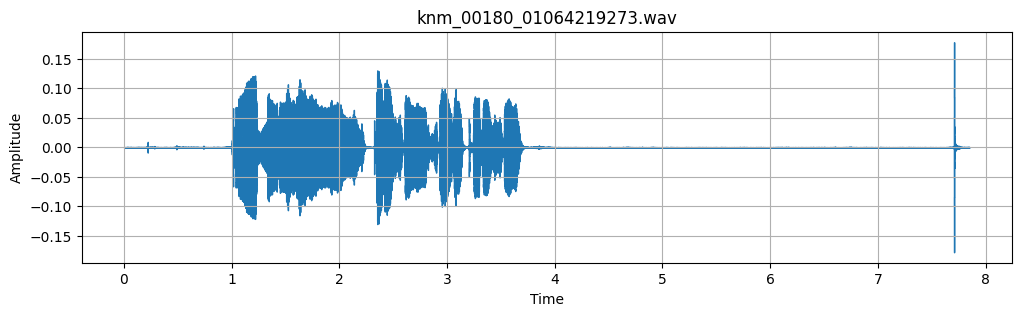


Analysis Complete ✅

Dataset pipeline and analysis completed in Colab.


In [1]:
!pip install -q indic_numtowords transformers datasets soundfile librosa accelerate sentencepiece


# ==================================================
# Logger
# ==================================================

def setup_logger(name=__name__):
    logger = logging.getLogger(name)
    if not logger.handlers:
        handler = logging.StreamHandler()
        handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
        logger.addHandler(handler)
        logger.setLevel(logging.INFO)
    return logger




import torch
print("Torch:", torch.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

# ============================================
# Kannada TTS Dataset Pipeline for Fine-Tuning
# Runs in Colab (uses /content as base)
# ============================================


import os
import zipfile
import requests
import pandas as pd
from tqdm import tqdm
import shutil
import random
import librosa
import soundfile as sf


# ============================================
# CONFIG
# ============================================

# In Colab we use /content as base
COLAB_BASE = "/content"

class DatasetConfig:
    WAV_ZIP_URL = "https://openslr.trmal.net/resources/79/kn_in_male.zip"
    TSV_URL       = "https://openslr.trmal.net/resources/79/line_index_male.tsv"

    # All paths under /content
    DATA_DIR      = os.path.join(COLAB_BASE, "kannada_tts_dataset")
    WAV_DIR       = os.path.join(DATA_DIR, "wavs")
    TEXT_DIR      = os.path.join(DATA_DIR, "text")
    ZIP_NAME      = "dataset.zip"
    TSV_NAME      = "metadata.tsv"


# ============================================
# DOWNLOADER
# ============================================

class DatasetDownloader:
    def __init__(self, config):
        self.config = config
        self.zip_path = os.path.join(config.DATA_DIR, config.ZIP_NAME)
        self.tsv_path = os.path.join(config.DATA_DIR, config.TSV_NAME)
        os.makedirs(config.DATA_DIR, exist_ok=True)

    def download_file(self, url, save_path):
        print(f"\nDownloading: {url}")
        response = requests.get(url, stream=True, timeout=30)
        total_size = int(response.headers.get("content-length", 0))
        with open(save_path, "wb") as f:
            for chunk in tqdm(response.iter_content(1024), total=total_size//1024, unit="KB"):
                f.write(chunk)
        print(f"Downloaded to: {save_path}")

    def run(self):
        if not os.path.exists(self.zip_path):
            self.download_file(self.config.WAV_ZIP_URL, self.zip_path)
        else:
            print("ZIP already exists — skipping download")

        if not os.path.exists(self.tsv_path):
            self.download_file(self.config.TSV_URL, self.tsv_path)
        else:
            print("TSV already exists — skipping download")


# ============================================
# EXTRACTOR
# ============================================

class DatasetExtractor:
    def __init__(self, config):
        self.config = config
        self.zip_path = os.path.join(config.DATA_DIR, config.ZIP_NAME)
        os.makedirs(config.WAV_DIR, exist_ok=True)
        os.makedirs(config.TEXT_DIR, exist_ok=True)

    def run(self):
        print("\nExtracting WAV files...")
        with zipfile.ZipFile(self.zip_path, "r") as zip_ref:
            zip_ref.extractall(self.config.WAV_DIR)
        print(f"Extraction completed. WAVs are in {self.config.WAV_DIR}")


# ============================================
# TEXT PREPARER
# ============================================

class TextPreparer:
    def __init__(self, config):
        self.config = config
        self.tsv_path = os.path.join(config.DATA_DIR, config.TSV_NAME)

    def run(self):
        print("\nPreparing text files...")
        df = pd.read_csv(self.tsv_path, sep="\t", header=None, names=["wav_file", "text"])
        for idx, row in df.iterrows():
            wav_file = str(row["wav_file"]).strip()
            text     = str(row["text"]).strip()
            text_file_path = os.path.join(self.config.TEXT_DIR, f"{wav_file}.txt")
            with open(text_file_path, "w", encoding="utf-8") as f:
                f.write(text)
        print(f"Text files saved in {self.config.TEXT_DIR}")
        print(f"Total text files: {len(df)}")
        return len(df)


# ============================================
# PIPELINE
# ============================================

class KannadaTTSPipeline:
    def __init__(self):
        self.config = DatasetConfig()
        self.downloader = DatasetDownloader(self.config)
        self.extractor  = DatasetExtractor(self.config)
        self.text_preparer = TextPreparer(self.config)

    def run(self):
        print("\n========== KANNADA TTS DATASET PIPELINE (Colab) ==========")
        print(f"Base directory: {os.path.dirname(self.config.DATA_DIR)}")
        print(f"Dataset location: {self.config.DATA_DIR}")
        print(f"WAV folder: {self.config.WAV_DIR}")
        print(f"Text folder: {self.config.TEXT_DIR}")

        self.downloader.run()
        self.extractor.run()
        total_texts = self.text_preparer.run()

        print("\n========== DATASET READY FOR FINE-TUNING ==========")
        print(f"Total text files: {total_texts}")
        print("You can now use this dataset for MMS‑TTS / VITS fine‑tuning.")




# ============================================
# Kannada TTS Dataset Analyzer
# ============================================

import matplotlib.pyplot as plt
import librosa
import librosa.display
import pandas as pd
from tqdm import tqdm
from IPython.display import Audio, display


class DatasetAnalyzer:

    def __init__(self, config):
        self.config = config
        self.tsv_path = os.path.join(config.DATA_DIR, config.TSV_NAME)


    def get_audio_info(self, path):
        try:
            audio, sr = librosa.load(path, sr=None)
            return len(audio) / sr, sr, len(audio)

        except Exception:
            return 0, 0, 0


    def plot_histogram(self, data, title, xlabel):
        plt.figure(figsize=(10, 4))
        plt.hist(data, bins=40)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel("Samples")
        plt.grid()
        plt.show()


    def plot_waveform(self, path):
        audio, sr = librosa.load(path, sr=None)

        plt.figure(figsize=(12, 3))
        librosa.display.waveshow(audio, sr=sr)
        plt.title(os.path.basename(path))
        plt.xlabel("Time")
        plt.ylabel("Amplitude")
        plt.grid()
        plt.show()


    def show_sample(self, row):

        wav_path = os.path.join(
            self.config.WAV_DIR,
            row.wav_file + ".wav"
        )

        print("\n" + "=" * 80)
        print(f"File: {row.wav_file}")
        print(f"Text: {row.text}")
        print(f"Duration: {row.duration:.2f}s | Sample Rate: {row.sample_rate} Hz")

        self.plot_waveform(wav_path)

        display(Audio(wav_path))


    def run(self, sample_count=5):

        print("\n========== DATASET ANALYSIS ==========")

        df = pd.read_csv(
            self.tsv_path,
            sep="\t",
            names=["wav_file", "text"]
        )

        print("Processing audio files...")

        audio_stats = []

        for file in tqdm(df.wav_file):

            path = os.path.join(
                self.config.WAV_DIR,
                file + ".wav"
            )

            duration, sr, samples = self.get_audio_info(path)

            audio_stats.append(
                [duration, sr, samples]
            )


        audio_df = pd.DataFrame(
            audio_stats,
            columns=[
                "duration",
                "sample_rate",
                "samples"
            ]
        )


        df = pd.concat(
            [df, audio_df],
            axis=1
        )


        df["text_length"] = df.text.str.len()


        print("\nDataset Summary")
        print("-" * 40)

        print(f"Total Samples     : {len(df)}")
        print(f"Total Hours       : {df.duration.sum()/3600:.2f}")
        print(f"Average Duration  : {df.duration.mean():.2f}s")
        print(f"Average Text Size : {df.text_length.mean():.1f} chars")


        print("\nSample Rates")
        print(df.sample_rate.value_counts())


        self.plot_histogram(
            df.duration,
            "Audio Duration Distribution",
            "Seconds"
        )


        self.plot_histogram(
            df.text_length,
            "Kannada Text Length Distribution",
            "Characters"
        )


        print("\n========== AUDIO EXAMPLES ==========")


        for _, row in df.sample(sample_count, random_state=42).iterrows():
            self.show_sample(row)


        print("\nAnalysis Complete ✅")

        return df
# ============================================
# ENTRY POINT
# ============================================

if __name__ == "__main__":
    # Ensure we are in /content (or it will be created anyway)
    os.makedirs("/content", exist_ok=True)

    pipeline = KannadaTTSPipeline()
    pipeline.run()

    # Run analysis after pipeline
    analyzer = DatasetAnalyzer(pipeline.config)
    analyzer.run(sample_count=5)

    print("\nDataset pipeline and analysis completed in Colab.")

In [2]:
# ==================================================
# HKL-VITS Hybrid Kannada TTS
# Full Final Version
# Classes 1 -> 10
# ==================================================

import os
import re
import math
import logging
from dataclasses import dataclass, field
from typing import Dict, List, Optional

import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from transformers import VitsModel, AutoTokenizer
from indic_numtowords import num2words



logger = setup_logger()


# ==================================================
# Class 1 - HKL CONFIG
# ==================================================

@dataclass
class HKLConfig:
    project_root: str = field(default_factory=lambda: os.getcwd())
    checkpoint_dir: str = "checkpoints"
    output_dir: str = "outputs"
    cache_dir: str = "cache"

    mms_model_name: str = "facebook/mms-tts-kan"
    model_revision: str = "main"

    use_cuda: bool = True
    cuda_device: int = 0
    sample_rate: int = 16000

    max_text_length: int = 512
    normalize_text: bool = True
    expand_numbers: bool = True
    expand_symbols: bool = True
    preserve_punctuation: bool = True
    lowercase_text: bool = False
    remove_number_commas: bool = True

    batch_size: int = 2
    epochs: int = 10
    learning_rate: float = 2e-4
    grad_accum_steps: int = 8
    freeze_mms: bool = True
    amp_enabled: bool = True
    checkpoint_every_epoch: bool = True

    dataset_wav_dir: str = "/content/kannada_tts_dataset/wavs"
    dataset_text_dir: str = "/content/kannada_tts_dataset/text"

    symbol_map: Dict[str, str] = field(default_factory=lambda: {
        "₹": "ರೂಪಾಯಿ",
        "$": "ಡಾಲರ್",
        "€": "ಯೂರೋ",
        "£": "ಪೌಂಡ್",
        "%": "ಶೇಕಡಾ",
        "+": "ಪ್ಲಸ್",
        "=": "ಸಮಾನ",
        "&": "ಮತ್ತು",
        "@": "ಅಟ್",
        "#": "ನಂಬರ್"
    })

    punctuation_map: Dict[str, str] = field(default_factory=lambda: {
        ".": " ... ",
        ",": " , ",
        "?": " ... ",
        "!": " ... ",
        ":": " , ",
        ";": " , "
    })

    def get_device(self):
        if self.use_cuda and torch.cuda.is_available():
            return f"cuda:{self.cuda_device}"
        return "cpu"

    def ensure_directories(self):
        os.makedirs(self.checkpoint_dir, exist_ok=True)
        os.makedirs(self.output_dir, exist_ok=True)
        os.makedirs(self.cache_dir, exist_ok=True)


# ==================================================
# Class 2 - Kannada Text Normalizer
# ==================================================

class KannadaTextNormalizer:
    def __init__(self, config: HKLConfig):
        self.config = config
        logger.info("KannadaTextNormalizer initialized")

    def normalize_whitespace(self, text):
        return re.sub(r"\s+", " ", text).strip()





    def replace_symbols(self, text):

      if not self.config.expand_symbols:
          return text


      for symbol, value in self.config.symbol_map.items():

        # Handle currency with optional spaces
        text = re.sub(
            rf"{re.escape(symbol)}\s*(\d+)",
            rf"{value} \1",
            text
        )


        text = text.replace(
            symbol,
            f" {value} "
        )

      return self.normalize_whitespace(text)


    def number_to_kannada(self, value):
        try:
            return num2words(value, lang="kn")
        except Exception as error:
            logger.warning("Number conversion failed %s : %s", value, error)
            return str(value)

    def expand_number_token(self, token):
        original = token
        clean = token.replace(",", "") if self.config.remove_number_commas else token
        clean_digits = re.match(r"^(\d+)(.*)$", clean)  # separate digits + suffix
        if not clean_digits:
            return original

        number_part, suffix = clean_digits.groups()
        if number_part.isdigit():
            expanded = self.number_to_kannada(int(number_part))
            return expanded + suffix  # reattach suffix
        return original


    def expand_numbers_text(self, text):
        if not self.config.expand_numbers:
            return text
        return " ".join(self.expand_number_token(x) for x in text.split())

    def process_punctuation(self, text):
        if self.config.preserve_punctuation:
            for p, value in self.config.punctuation_map.items():
                text = text.replace(p, value)
        return text




    def normalize(self, text):

      if not text:
          return ""
      if self.config.lowercase_text:
          text = text.lower()
      # protect currency numbers first
      text = re.sub(r"₹\s*(\d+)", r"₹\1",text)
      text = self.normalize_whitespace(text)
      text = self.replace_symbols(text)
      # expand numbers after currency cleanup
      text = self.expand_numbers_text(text)
      text = self.process_punctuation(text)
      return self.normalize_whitespace(text)




    def tokenize(self, text) -> List[str]:
        return self.normalize(text).split()


# ==================================================
# Class 4 - Kannada Phoneme Tokenizer
# ==================================================

class KannadaPhonemeTokenizer:
    def __init__(self):
        self.phonemes = [
            "<pad>", "<unk>",
            "a", "aa", "i", "ii", "u", "uu", "e", "ee", "o", "oo",
            "ka", "kha", "ga", "gha",
            "cha", "ja",
            "ṭa", "ṭha", "ɖa", "ɖha",
            "ta", "tha", "da", "dha",
            "na", "ṇa", "ɳ",
            "pa", "pha", "ba", "bha",
            "ma",
            "ya", "ra", "la", "va",
            "sha", "ṣa", "sa", "ha",
            "pra", "kra", "ksha", "tra", "gra",
            "ː"
        ]
        self.phoneme_to_id = {p: i for i, p in enumerate(self.phonemes)}
        self.id_to_phoneme = {i: p for p, i in self.phoneme_to_id.items()}

    def encode(self, text):
        return [self.phoneme_to_id.get(x, self.phoneme_to_id["<unk>"]) for x in text.split()]

    def decode(self, ids):
        return " ".join(self.id_to_phoneme.get(i, "<unk>") for i in ids)

    @property
    def vocab_size(self):
        return len(self.phonemes)


# ==================================================
# Class 5 - Kannada G2P FINAL
# ==================================================



class HKLKannadaG2P:
    def __init__(self):
        self.map = {
            "ಅ": "a", "ಆ": "aa", "ಇ": "i", "ಈ": "ii", "ಉ": "u", "ಊ": "uu",
            "ಕ": "ka", "ಖ": "kha", "ಗ": "ga", "ಘ": "gha",
            "ಚ": "cha", "ಜ": "ja",
            "ಟ": "ṭa", "ಠ": "ṭha", "ಡ": "ɖa", "ಢ": "ɖha",
            "ತ": "ta", "ಥ": "tha", "ದ": "da", "ಧ": "dha",
            "ನ": "na", "ಣ": "ṇa",
            "ಪ": "pa", "ಫ": "pha", "ಬ": "ba", "ಭ": "bha",
            "ಮ": "ma",
            "ಯ": "ya", "ರ": "ra", "ಲ": "la", "ವ": "va",
            "ಶ": "sha", "ಷ": "ṣa", "ಸ": "sa", "ಹ": "ha"
        }

        self.matra = {
            "ಾ": "aa", "ಿ": "i", "ೀ": "ii", "ು": "u", "ೂ": "uu",
            "ೆ": "e", "ೇ": "ee", "ೊ": "o", "ೋ": "oo"
        }

        self.conjuncts = {
            "ಕ್ಷ": "ksha",
            "ಪ್ರ": "pra",
            "ಕ್ರ": "kra",
            "ಗ್ರ": "gra",
            "ತ್ರ": "tra"
        }

    def convert_word(self, word: str) -> str:
        """Convert a single Kannada word into phoneme sequence."""
        # Handle conjuncts first
        for c, v in self.conjuncts.items():
            if c in word:
                word = word.replace(c, f" {{{v}}} ")

        output = []
        i = 0
        while i < len(word):
            ch = word[i]

            # Handle explicit conjunct markers
            if ch == "{":
                token = ""
                i += 1
                while i < len(word) and word[i] != "}":
                    token += word[i]
                    i += 1
                output.append(token)
                i += 1
                continue

            if ch in self.map:
                sound = self.map[ch]
                if i + 1 < len(word):
                    nxt = word[i + 1]
                    if nxt == "್":  # halant
                        sound = sound[:-1] + "ː"
                        i += 1
                    elif nxt in self.matra:
                        sound = sound[:-1] + self.matra[nxt]
                        i += 1
                output.append(sound)

            elif ch == "ಂ":  # anusvara
                output.append("m")

            elif ch == "ಃ":  # visarga
                output.append("h")

            i += 1

        return " ".join(output)

    def convert_sentence(self, text: str) -> list:
        """Convert a full sentence into list of phoneme sequences per word."""
        return [self.convert_word(word) for word in text.split()]

    def to_phoneme_string(self, text: str) -> str:
        """Convert sentence and return a single phoneme string."""
        return " ".join(self.convert_sentence(text))

    def debug_print(self, text: str):
        """Utility: print original, normalized, and phoneme conversion."""
        print("Original:", text)
        print("Phoneme:", self.to_phoneme_string(text))


# ==================================================
# Class 6 - Simple Grapheme Tokenizer
# ==================================================

class SimpleCharTokenizer:
    def __init__(self, extra_tokens=None):
        base_chars = list(
            " ಅಆಇಈಉಊಋಎಏಐಒಓಔ"
            "ಕಖಗಘಙಚಛಜಝಞಟಠಡಢಣತಥದಧನ"
            "ಪಫಬಭಮಯರಲವಶಷಸಹಳ"
            "ಾಿೀುೂೃೆೇೈೊೋೌಂಃ್"
            "0123456789"
            ".,?!:;-()"
        )
        tokens = ["<pad>", "<unk>"] + sorted(set(base_chars + (extra_tokens or [])))
        self.char_to_id = {ch: i for i, ch in enumerate(tokens)}
        self.id_to_char = {i: ch for ch, i in self.char_to_id.items()}

    def encode(self, text):
        return [self.char_to_id.get(ch, self.char_to_id["<unk>"]) for ch in text]

    @property
    def vocab_size(self):
        return len(self.char_to_id)


# ==================================================
# Class 7 - HKL Linguistic Encoder + Prosody
# ==================================================

class KannadaGraphemeEncoder(nn.Module):
    def __init__(self, vocab, hidden=256):
        super().__init__()
        self.embed = nn.Embedding(vocab, hidden)
        self.encoder = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(hidden, 4, batch_first=True),
            4
        )

    def forward(self, x):
        return self.encoder(self.embed(x))


class KannadaPhonemeEncoder(nn.Module):
    def __init__(self, vocab, hidden=256):
        super().__init__()
        self.embed = nn.Embedding(vocab, hidden)
        self.lstm = nn.LSTM(hidden, hidden // 2, 2, batch_first=True, bidirectional=True)

    def forward(self, x):
        return self.lstm(self.embed(x))[0]


class HKLFusionAttention(nn.Module):
    def __init__(self, hidden=256):
        super().__init__()
        self.attn = nn.MultiheadAttention(hidden, 4, batch_first=True)
        self.norm = nn.LayerNorm(hidden)

    def forward(self, g, p):
        if g.size(1) != p.size(1):
            p = F.interpolate(p.transpose(1, 2), size=g.size(1), mode="nearest").transpose(1, 2)
        x, _ = self.attn(g, p, p)
        return self.norm(g + x)


class HKLVITSLinguisticEncoder(nn.Module):
    def __init__(self, g_vocab, p_vocab):
        super().__init__()
        self.g = KannadaGraphemeEncoder(g_vocab)
        self.p = KannadaPhonemeEncoder(p_vocab)
        self.fusion = HKLFusionAttention()

    def forward(self, g_ids, p_ids):
        return self.fusion(self.g(g_ids), self.p(p_ids))


class KannadaProsodyModel(nn.Module):
    def __init__(self, hidden_dim=256, prosody_dim=4):
        super().__init__()
        self.encoder = nn.LSTM(
            input_size=hidden_dim,
            hidden_size=hidden_dim // 2,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.1
        )
        self.norm = nn.LayerNorm(hidden_dim)
        self.projection = nn.Linear(hidden_dim, hidden_dim)
        self.output = nn.Linear(hidden_dim, prosody_dim)

    def forward(self, linguistic_features):
        x, _ = self.encoder(linguistic_features)
        x = self.norm(x)
        hidden = self.projection(x)
        prosody = self.output(hidden)

        return {
            "hidden": hidden,
            "pause": prosody[:, :, 0],
            "duration": prosody[:, :, 1],
            "pitch": prosody[:, :, 2],
            "energy": prosody[:, :, 3]
        }


# ==================================================
# Class 8 - HKL-VITS Wrapper + Inference Helper
# ==================================================

class HKLVITS(nn.Module):
    def __init__(
        self,
        mms_model_name,
        linguistic_encoder,
        prosody_model,
        hkl_hidden_dim=256,
        freeze_mms=True
    ):
        super().__init__()

        self.mms = VitsModel.from_pretrained(mms_model_name)
        self.mms_hidden_dim = self.mms.config.hidden_size

        self.linguistic_encoder = linguistic_encoder
        self.prosody_model = prosody_model
        self.hkl_projection = nn.Linear(hkl_hidden_dim, self.mms_hidden_dim)

        if freeze_mms:
            for p in self.mms.parameters():
                p.requires_grad = False

    def forward(self, input_ids, phoneme_ids, attention_mask=None):
        hkl_features = self.linguistic_encoder(input_ids, phoneme_ids)
        prosody = self.prosody_model(hkl_features)
        mms_features = self.hkl_projection(prosody["hidden"])

        output = self.mms(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        return {
            "waveform": output.waveform,
            "spectrogram": output.spectrogram,
            "hkl_features": hkl_features,
            "mms_features": mms_features,
            "prosody": prosody
        }


class HKLVITSInference:
    def __init__(
        self,
        model,
        tokenizer,
        normalizer,
        g2p,
        phoneme_tokenizer,
        device
    ):
        self.model = model
        self.tokenizer = tokenizer
        self.normalizer = normalizer
        self.g2p = g2p
        self.phoneme_tokenizer = phoneme_tokenizer
        self.device = device

    def synthesize(self, text):
        normalized_text = self.normalizer.normalize(text)

        inputs = self.tokenizer(
            normalized_text,
            return_tensors="pt"
        )

        input_ids = inputs.input_ids.to(self.device)
        attention_mask = inputs.attention_mask.to(self.device) if "attention_mask" in inputs else None

        phoneme_text = " ".join(self.g2p.convert_sentence(normalized_text))
        phoneme_ids_list = self.phoneme_tokenizer.encode(phoneme_text)
        if len(phoneme_ids_list) == 0:
            phoneme_ids_list = [self.phoneme_tokenizer.phoneme_to_id["<pad>"]]

        phoneme_ids = torch.tensor(
            phoneme_ids_list,
            dtype=torch.long
        ).unsqueeze(0).to(self.device)

        with torch.no_grad():
            output = self.model(
                input_ids=input_ids,
                phoneme_ids=phoneme_ids,
                attention_mask=attention_mask
            )

        return {
            "normalized_text": normalized_text,
            "phoneme_text": phoneme_text,
            "output": output
        }


# ==================================================
# Class 9 - Dataset + Collator + Trainer Model
# ==================================================

class HKLDataset(Dataset):
    def __init__(
        self,
        wav_dir,
        text_dir,
        tokenizer,
        normalizer,
        g2p,
        phoneme_tokenizer,
        sample_rate=16000,
        load_audio=True
    ):
        self.items = []
        self.tokenizer = tokenizer
        self.normalizer = normalizer
        self.g2p = g2p
        self.phoneme_tokenizer = phoneme_tokenizer
        self.sample_rate = sample_rate
        self.load_audio = load_audio

        if not os.path.isdir(wav_dir) or not os.path.isdir(text_dir):
            logger.warning("Dataset directories not found: %s | %s", wav_dir, text_dir)
            return

        for txt in sorted(os.listdir(text_dir)):
            if not txt.endswith(".txt"):
                continue

            base = txt[:-4]
            wav = os.path.join(wav_dir, base + ".wav")
            txt_path = os.path.join(text_dir, txt)

            if not os.path.exists(wav):
                continue

            with open(txt_path, encoding="utf8") as f:
                raw_text = f.read().strip()

            normalized_text = self.normalizer.normalize(raw_text)
            phoneme_text = " ".join(self.g2p.convert_sentence(normalized_text))

            self.items.append({
                "wav": wav,
                "text": raw_text,
                "normalized_text": normalized_text,
                "phoneme_text": phoneme_text
            })

        print("Dataset size:", len(self.items))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        item = self.items[idx]

        tok = self.tokenizer(
            item["normalized_text"],
            return_tensors="pt",
            truncation=True
        )
        input_ids = tok.input_ids.squeeze(0)
        attention_mask = tok.attention_mask.squeeze(0)

        phoneme_ids = self.phoneme_tokenizer.encode(item["phoneme_text"])
        if len(phoneme_ids) == 0:
            phoneme_ids = [self.phoneme_tokenizer.phoneme_to_id["<pad>"]]
        phoneme_ids = torch.tensor(phoneme_ids, dtype=torch.long)

        result = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "phoneme_ids": phoneme_ids,
            "text": item["text"],
            "normalized_text": item["normalized_text"],
            "phoneme_text": item["phoneme_text"]
        }

        if self.load_audio:
            audio, sr = sf.read(item["wav"])
            audio = torch.tensor(audio, dtype=torch.float32)
            if audio.ndim > 1:
                audio = audio.mean(dim=-1)
            result["audio"] = audio
            result["audio_length"] = torch.tensor(len(audio), dtype=torch.long)
            result["sample_rate"] = sr

        return result


class HKLCollator:
    def __init__(self, pad_id, phoneme_pad_id=0, device="cpu"):
        self.pad_id = pad_id
        self.phoneme_pad_id = phoneme_pad_id
        self.device = device

    def __call__(self, batch):
        input_ids = torch.nn.utils.rnn.pad_sequence(
            [x["input_ids"] for x in batch],
            batch_first=True,
            padding_value=self.pad_id
        )

        attention_mask = torch.nn.utils.rnn.pad_sequence(
            [x["attention_mask"] for x in batch],
            batch_first=True,
            padding_value=0
        )

        phoneme_ids = torch.nn.utils.rnn.pad_sequence(
            [x["phoneme_ids"] for x in batch],
            batch_first=True,
            padding_value=self.phoneme_pad_id
        )

        result = {
            "input_ids": input_ids.to(self.device),
            "attention_mask": attention_mask.to(self.device),
            "phoneme_ids": phoneme_ids.to(self.device),
            "texts": [x["text"] for x in batch],
            "normalized_texts": [x["normalized_text"] for x in batch],
            "phoneme_texts": [x["phoneme_text"] for x in batch],
        }

        if "audio" in batch[0]:
            audio = torch.nn.utils.rnn.pad_sequence(
                [x["audio"] for x in batch],
                batch_first=True,
                padding_value=0.0
            )
            audio_length = torch.stack([x["audio_length"] for x in batch])

            result["audio"] = audio.to(self.device)
            result["audio_length"] = audio_length.to(self.device)

        return result


class HKLTrainerModel(nn.Module):
    def __init__(
        self,
        mms,
        linguistic_encoder,
        prosody_model,
        freeze_mms=True
    ):
        super().__init__()

        self.mms = mms
        self.linguistic_encoder = linguistic_encoder
        self.prosody_model = prosody_model

        if freeze_mms:
            for p in self.mms.parameters():
                p.requires_grad = False

        self.adapter = nn.Linear(256, self.mms.config.hidden_size)
        self.duration_head = nn.Linear(256, 1)
        self.pitch_head = nn.Linear(256, 1)
        self.energy_head = nn.Linear(256, 1)

    def forward(self, input_ids, phoneme_ids, attention_mask=None):
        hkl_features = self.linguistic_encoder(input_ids, phoneme_ids)
        prosody = self.prosody_model(hkl_features)
        mms_features = self.adapter(prosody["hidden"])

        duration = self.duration_head(prosody["hidden"]).squeeze(-1)
        pitch = self.pitch_head(prosody["hidden"]).squeeze(-1)
        energy = self.energy_head(prosody["hidden"]).squeeze(-1)

        return {
            "features": hkl_features,
            "prosody_hidden": prosody["hidden"],
            "pause": prosody["pause"],
            "duration": duration,
            "pitch": pitch,
            "energy": energy,
            "mms_features": mms_features
        }


# ==================================================
# Class 10 - Loss + Training + Final Inference
# ==================================================

class HKLLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.mse = nn.MSELoss()

    def phoneme_clarity_loss(self, x):
        if x.size(1) < 2:
            return torch.tensor(0.0, device=x.device)
        diff = x[:, 1:] - x[:, :-1]
        distance = torch.norm(diff, dim=-1)
        margin = 1.0
        return torch.relu(margin - distance).mean()

    def forward(self, output):
        features = output["features"]
        prosody_hidden = output["prosody_hidden"]
        pause = output["pause"]
        duration = output["duration"]
        pitch = output["pitch"]
        energy = output["energy"]

        feature_loss = torch.mean(features ** 2)
        hidden_loss = torch.mean(prosody_hidden ** 2)
        pause_loss = torch.mean(pause ** 2)
        duration_loss = torch.mean(duration ** 2)
        pitch_loss = torch.mean(pitch ** 2)
        energy_loss = torch.mean(energy ** 2)
        clarity = self.phoneme_clarity_loss(features)

        total = (
            0.20 * feature_loss +
            0.20 * hidden_loss +
            0.10 * pause_loss +
            0.15 * duration_loss +
            0.15 * pitch_loss +
            0.10 * energy_loss +
            0.10 * clarity
        )

        return total


def build_pipeline(config: HKLConfig):
    config.ensure_directories()
    device = config.get_device()

    normalizer = KannadaTextNormalizer(config)
    g2p = HKLKannadaG2P()
    phoneme_tokenizer = KannadaPhonemeTokenizer()
    grapheme_tokenizer = SimpleCharTokenizer()

    tokenizer = AutoTokenizer.from_pretrained(config.mms_model_name)
    if tokenizer.pad_token_id is None:
        if tokenizer.eos_token is not None:
            tokenizer.pad_token = tokenizer.eos_token
        else:
            tokenizer.add_special_tokens({"pad_token": "<pad>"})

    linguistic_encoder = HKLVITSLinguisticEncoder(
        g_vocab=256,
        p_vocab=phoneme_tokenizer.vocab_size
    ).to(device)

    prosody_model = KannadaProsodyModel(hidden_dim=256).to(device)

    hkl_vits = HKLVITS(
        mms_model_name=config.mms_model_name,
        linguistic_encoder=linguistic_encoder,
        prosody_model=prosody_model,
        hkl_hidden_dim=256,
        freeze_mms=config.freeze_mms
    ).to(device)

    trainer_model = HKLTrainerModel(
        mms=hkl_vits.mms,
        linguistic_encoder=linguistic_encoder,
        prosody_model=prosody_model,
        freeze_mms=config.freeze_mms
    ).to(device)

    return {
        "device": device,
        "normalizer": normalizer,
        "g2p": g2p,
        "phoneme_tokenizer": phoneme_tokenizer,
        "grapheme_tokenizer": grapheme_tokenizer,
        "tokenizer": tokenizer,
        "linguistic_encoder": linguistic_encoder,
        "prosody_model": prosody_model,
        "hkl_vits": hkl_vits,
        "trainer_model": trainer_model
    }


def train_hkl_vits(config: HKLConfig, pipeline):
    device = pipeline["device"]
    tokenizer = pipeline["tokenizer"]
    normalizer = pipeline["normalizer"]
    g2p = pipeline["g2p"]
    phoneme_tokenizer = pipeline["phoneme_tokenizer"]
    model = pipeline["trainer_model"]

    dataset = HKLDataset(
        wav_dir=config.dataset_wav_dir,
        text_dir=config.dataset_text_dir,
        tokenizer=tokenizer,
        normalizer=normalizer,
        g2p=g2p,
        phoneme_tokenizer=phoneme_tokenizer,
        sample_rate=config.sample_rate,
        load_audio=True
    )

    if len(dataset) == 0:
        print("No training data found. Skipping training.")
        return None

    loader = DataLoader(
        dataset,
        batch_size=config.batch_size,
        shuffle=True,
        collate_fn=HKLCollator(
            pad_id=tokenizer.pad_token_id,
            phoneme_pad_id=phoneme_tokenizer.phoneme_to_id["<pad>"],
            device=device
        )
    )

    criterion = HKLLoss()
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=config.learning_rate
    )

    scaler = torch.amp.GradScaler("cuda", enabled=(config.amp_enabled and str(device).startswith("cuda")))

    print("=" * 60)
    print("Starting HKL-VITS Training")
    print("Device:", device)
    print("Dataset size:", len(dataset))
    print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))
    print("=" * 60)

    global_step = 0
    last_checkpoint = None

    for epoch in range(config.epochs):
        model.train()
        epoch_loss = 0.0

        loop = tqdm(loader, desc=f"Epoch {epoch + 1}/{config.epochs}")
        optimizer.zero_grad(set_to_none=True)

        for step, batch in enumerate(loop):
            use_amp = config.amp_enabled and str(device).startswith("cuda")
            with torch.amp.autocast("cuda", enabled=use_amp):
                output = model(
                    input_ids=batch["input_ids"],
                    phoneme_ids=batch["phoneme_ids"],
                    attention_mask=batch["attention_mask"]
                )
                loss = criterion(output)
                loss = loss / config.grad_accum_steps

            scaler.scale(loss).backward()

            if (step + 1) % config.grad_accum_steps == 0 or (step + 1) == len(loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                global_step += 1

            epoch_loss += loss.item()
            loop.set_postfix(loss=loss.item() * config.grad_accum_steps)

        avg = epoch_loss / len(loader)
        print(f"\nEpoch {epoch + 1} Loss: {avg:.6f}")

        if config.checkpoint_every_epoch:
            ckpt_path = os.path.join(
                config.checkpoint_dir,
                f"hkl_vits_epoch_{epoch + 1}.pt"
            )
            torch.save({
                "epoch": epoch + 1,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "config": config.__dict__
            }, ckpt_path)
            print("Saved:", ckpt_path)
            last_checkpoint = ckpt_path

    print("=" * 60)
    print("HKL-VITS TRAINING COMPLETE")
    print("=" * 60)

    return last_checkpoint


def load_trained_model_for_inference(config: HKLConfig, checkpoint_path: str):
    pipeline = build_pipeline(config)
    model = pipeline["trainer_model"]
    device = pipeline["device"]

    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model"])
    model.eval()

    return pipeline


def synthesize_with_mms_backbone(config: HKLConfig, pipeline, text: str, output_path: Optional[str] = None):
    device = pipeline["device"]
    tokenizer = pipeline["tokenizer"]
    normalizer = pipeline["normalizer"]
    g2p = pipeline["g2p"]
    phoneme_tokenizer = pipeline["phoneme_tokenizer"]
    trainer_model = pipeline["trainer_model"]
    mms = trainer_model.mms

    normalized_text = normalizer.normalize(text)
    inputs = tokenizer(normalized_text, return_tensors="pt")
    input_ids = inputs.input_ids.to(device)
    attention_mask = inputs.attention_mask.to(device) if "attention_mask" in inputs else None

    phoneme_text = " ".join(g2p.convert_sentence(normalized_text))
    phoneme_ids = phoneme_tokenizer.encode(phoneme_text)
    if len(phoneme_ids) == 0:
        phoneme_ids = [phoneme_tokenizer.phoneme_to_id["<pad>"]]
    phoneme_ids = torch.tensor(phoneme_ids, dtype=torch.long).unsqueeze(0).to(device)

    with torch.no_grad():
        hkl = trainer_model(
            input_ids=input_ids,
            phoneme_ids=phoneme_ids,
            attention_mask=attention_mask
        )

        mms_out = mms(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        wav = mms_out.waveform.squeeze().detach().cpu().numpy()

    if output_path is None:
        output_path = os.path.join(config.output_dir, "hkl_vits_output.wav")

    sf.write(output_path, wav, config.sample_rate)

    print("\nInput:", text)
    print("Normalized:", normalized_text)
    print("Phoneme:", phoneme_text)
    print("HKL features:", hkl["features"].shape)
    print("Prosody hidden:", hkl["prosody_hidden"].shape)
    print("Waveform:", wav.shape)
    print("Saved audio:", output_path)

    return output_path, wav

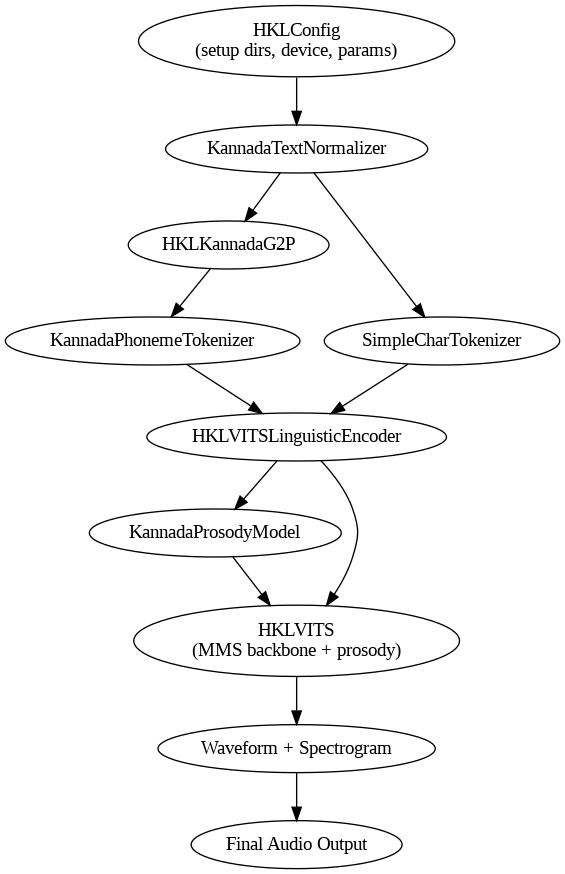

In [3]:
from graphviz import Digraph, Source
from IPython.display import Image

dot = Digraph(comment="HKL-VITS Flow")

# Example nodes (same as before)
dot.node("Config", "HKLConfig\n(setup dirs, device, params)")
dot.node("Normalizer", "KannadaTextNormalizer")
dot.node("G2P", "HKLKannadaG2P")
dot.node("PhonemeTok", "KannadaPhonemeTokenizer")
dot.node("CharTok", "SimpleCharTokenizer")
dot.node("LingEnc", "HKLVITSLinguisticEncoder")
dot.node("Prosody", "KannadaProsodyModel")
dot.node("HKLVITS", "HKLVITS\n(MMS backbone + prosody)")
dot.node("Output", "Waveform + Spectrogram")
dot.node("FinalAudio", "Final Audio Output")

# Example edges
dot.edges([
    ("Config", "Normalizer"),
    ("Normalizer", "G2P"),
    ("G2P", "PhonemeTok"),
    ("Normalizer", "CharTok"),
    ("CharTok", "LingEnc"),
    ("PhonemeTok", "LingEnc"),
    ("LingEnc", "Prosody"),
    ("LingEnc", "HKLVITS"),
    ("Prosody", "HKLVITS"),
    ("HKLVITS", "Output"),
    ("Output", "FinalAudio")
])

# Render and display inline in Colab
dot.render("hkl_vits_flow", format="png", cleanup=True)
Image(filename="hkl_vits_flow.png")


In [4]:
# ==================================================
# Training + Final Inference
# ==================================================

from IPython.display import Audio, display

config = HKLConfig()
pipeline = build_pipeline(config)

RUN_TRAINING = True
RUN_FINAL_INFERENCE = True
PLAY_AUDIO_IN_COLAB = True

FINAL_TEXT = """
ನಮಸ್ಕಾರ, ನಾನು ಕನ್ನಡ ಮಾತನಾಡುತ್ತೇನೆ.
ಈ ಪುಸ್ತಕದ ಬೆಲೆ ₹250 ಆಗಿದೆ ಮತ್ತು ಇದು 2026ರಲ್ಲಿ ಪ್ರಕಟಿಸಲಾಯಿತು.
ಭಾರತವು ವಿಶ್ವದ ಅತ್ಯಂತ ದೊಡ್ಡ ಪ್ರಜಾಪ್ರಭುತ್ವ ರಾಷ್ಟ್ರವಾಗಿದೆ!
"""

final_audio_path = os.path.join(config.output_dir, "final_kannada_tts.wav")

def play_audio_in_colab(audio_path: str, autoplay: bool = False):
    if not os.path.exists(audio_path):
        logger.warning("Audio file not found for playback: %s", audio_path)
        return
    logger.info("Rendering audio player in Colab: %s", audio_path)
    display(Audio(audio_path, autoplay=autoplay))

# ----------------------------------------------
# Training
# ----------------------------------------------
last_checkpoint = None
if RUN_TRAINING:
    last_checkpoint = train_hkl_vits(config, pipeline)

# ----------------------------------------------
# Final inference
# ----------------------------------------------
if RUN_FINAL_INFERENCE:
    ckpt = last_checkpoint
    if ckpt is None:
        candidate = os.path.join(config.checkpoint_dir, f"hkl_vits_epoch_{config.epochs}.pt")
        if os.path.exists(candidate):
            ckpt = candidate

    if ckpt and os.path.exists(ckpt):
        logger.info("Using checkpoint for final inference: %s", ckpt)
        infer_pipeline = load_trained_model_for_inference(config, ckpt)
    else:
        logger.warning("No checkpoint found. Running inference with current pipeline backbone only.")
        infer_pipeline = pipeline

    synthesize_with_mms_backbone(
        config=config,
        pipeline=infer_pipeline,
        text=FINAL_TEXT,
        output_path=final_audio_path
    )

    if PLAY_AUDIO_IN_COLAB and os.path.exists(final_audio_path):
        play_audio_in_colab(final_audio_path, autoplay=False)

2026-07-24 14:34:39,891 | INFO | KannadaTextNormalizer initialized
INFO:__main__:KannadaTextNormalizer initialized


config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/940 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/47.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

... (24 outputs left out)

Saved: checkpoints/hkl_vits_epoch_10.pt
HKL-VITS TRAINING COMPLETE


Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

2026-07-24 14:41:54,261 | INFO | Rendering audio player in Colab: outputs/final_kannada_tts.wav
INFO:__main__:Rendering audio player in Colab: outputs/final_kannada_tts.wav



Input: 
ನಮಸ್ಕಾರ, ನಾನು ಕನ್ನಡ ಮಾತನಾಡುತ್ತೇನೆ.
ಈ ಪುಸ್ತಕದ ಬೆಲೆ ₹250 ಆಗಿದೆ ಮತ್ತು ಇದು 2026ರಲ್ಲಿ ಪ್ರಕಟಿಸಲಾಯಿತು.
ಭಾರತವು ವಿಶ್ವದ ಅತ್ಯಂತ ದೊಡ್ಡ ಪ್ರಜಾಪ್ರಭುತ್ವ ರಾಷ್ಟ್ರವಾಗಿದೆ!

Normalized: ನಮಸ್ಕಾರ , ನಾನು ಕನ್ನಡ ಮಾತನಾಡುತ್ತೇನೆ ... ಈ ಪುಸ್ತಕದ ಬೆಲೆ ರೂಪಾಯಿ ಇನ್ನೂ ಆಗಿದೆ ಮತ್ತು ಇದು ಎರಡು ಸಾವಿರದ ಇಪ್ಪತ್ತಾರುರಲ್ಲಿ ಪ್ರಕಟಿಸಲಾಯಿತು ... ಭಾರತವು ವಿಶ್ವದ ಅತ್ಯಂತ ದೊಡ್ಡ ಪ್ರಜಾಪ್ರಭುತ್ವ ರಾಷ್ಟ್ರವಾಗಿದೆ ...
Phoneme: na ma sː kaa ra  naa nu ka nː na ɖa maa ta naa ɖu tː tee ne  ii pu sː ta ka da be le ruu paa yi i nː nuu aa gi de ma tː tu i du ra ɖu saa vi ra da i pː pa tː taa ru ra lː li pra ka ṭi sa laa yi tu  bhaa ra ta vu vi shː va da a tː ya m ta do ɖː ɖa pra jaa pra bhu tː va raa ṣː ṭː ra vaa gi de 
HKL features: torch.Size([1, 353, 256])
Prosody hidden: torch.Size([1, 353, 256])
Waveform: (289536,)
Saved audio: outputs/final_kannada_tts.wav


In [5]:
!pip install -q psutil
!pip install -q pesq
!pip install -q pystoi
!pip install -q jiwer
!pip install -q evaluate
!pip install -q librosa
!pip install -q pyworld
!pip install -q praat-parselmouth
!pip install -q mir_eval
!pip install -q pynvml
!pip install -q matplotlib
!pip install -q pandas
!pip install -q scipy
!pip install -q numpy

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.0/261.0 kB 6.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 98.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.8/102.8 kB 3.8 MB/s eta 0:00:00


In [24]:
#!/usr/bin/env python3
"""Notebook-friendly HKL-VITS quality and performance testing harness.

This evaluator is designed for a notebook or Colab runtime where the training
and inference objects already exist in scope. It benchmarks both objective
speech quality and runtime performance.

The script intentionally keeps the notebook-facing API simple:
- `NotebookQualityConfig`
- `run_in_notebook_quality_eval(...)`
- `run_quality_testing_in_notebook(...)`

It computes a broad set of metrics when the required libraries are installed:
- latency / throughput / repeatability
- waveform and spectrum statistics
- pitch statistics (F0)
- PESQ, STOI, WER, CER and MCD when reference audio/text are available
- CPU, RAM and GPU resource usage
- optional plots and a JSON summary report
"""

from __future__ import annotations

import importlib
import inspect
import json
import logging
import os
import statistics
import time
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Callable, Dict, List, Optional, Tuple

import numpy as np
import soundfile as sf
from tqdm.auto import tqdm

librosa = None
psutil = None
pd = None
plt = None
pesq_score_fn = None
stoi_score_fn = None
jiwer_wer = None
jiwer_cer = None
load_hf_metric = None
pw = None
parselmouth = None
mir_eval = None
pynvml = None
torch = None

for module_name in (
    "librosa",
    "psutil",
    "pandas",
    "matplotlib.pyplot",
    "pesq",
    "pystoi",
    "jiwer",
    "evaluate",
    "pyworld",
    "parselmouth",
    "mir_eval",
    "pynvml",
    "torch",
):
    try:
        module = importlib.import_module(module_name)
        if module_name == "librosa":
            librosa = module
        elif module_name == "psutil":
            psutil = module
        elif module_name == "pandas":
            pd = module
        elif module_name == "matplotlib.pyplot":
            plt = module
        elif module_name == "pesq":
            pesq_score_fn = module.pesq
        elif module_name == "pystoi":
            stoi_score_fn = module.stoi
        elif module_name == "jiwer":
            jiwer_wer = module.wer
            jiwer_cer = module.cer
        elif module_name == "evaluate":
            load_hf_metric = module.load
        elif module_name == "pyworld":
            pw = module
        elif module_name == "parselmouth":
            parselmouth = module
        elif module_name == "mir_eval":
            mir_eval = module
        elif module_name == "pynvml":
            pynvml = module
        elif module_name == "torch":
            torch = module
    except Exception:
        pass


# Notebook compatibility: allow the file to be imported without the training
# cell already having executed. The real notebook objects are optional here.
config: Any = globals().get("config")
pipeline: Any = globals().get("pipeline")

logger = logging.getLogger("notebook_quality_eval")
if not logger.handlers:
    handler = logging.StreamHandler()
    handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
    logger.addHandler(handler)
    logger.setLevel(logging.INFO)


@dataclass
class NotebookQualityConfig:
    dataset_dir: str = "/content/kannada_tts_dataset"
    wav_dir: str = "/content/kannada_tts_dataset/wavs"
    text_dir: str = "/content/kannada_tts_dataset/text"
    output_dir: str = "/content/quality_eval"
    reference_wav_dir: str = "/content/kannada_tts_dataset/wavs"
    sample_rate: int = 16000
    sample_limit: int = 100
    repeat_per_sample: int = 3
    fallback_samples: List[Dict[str, str]] = field(
        default_factory=lambda: [
            {"id": "sample_01", "name": "Simple greeting", "text": "ನಮಸ್ಕಾರ"},
            {"id": "sample_02", "name": "Number", "text": "2500"},
            {"id": "sample_03", "name": "Currency", "text": "₹2500"},
            {"id": "sample_04", "name": "Percentage", "text": "50%"},
            {"id": "sample_05", "name": "Mixed language", "text": "ಬೆಂಗಳೂರು City"},
            {"id": "sample_06", "name": "Question sentence", "text": "ನೀವು ಹೇಗಿದ್ದೀರಿ?"},
            {"id": "sample_07", "name": "Long paragraph", "text": "ಕನ್ನಡವು ಒಂದು ಪ್ರಾಚೀನ ಭಾಷೆಯಾಗಿದ್ದು, ಅದರಲ್ಲಿ ಸಾಹಿತ್ಯ ಮತ್ತು ಸಂಸ್ಕೃತಿ ಬಹಳ ಆಳವಾಗಿಟ್ಟುಕೊಂಡಿದೆ. ಈ ಭಾಷೆಯ ಧ್ವವಿಮಾಧ್ಯಮದ ಗುಣಮಟ್ಟ ಮತ್ತು ಅರ್ಥಪೂರ್ಣತೆ ಬಹಳ ಮುಖ್ಯವಾಗಿದೆ."},
            {"id": "sample_08", "name": "Conjunct consonant", "text": "ಕ್ಷೇತ್ರ"},
        ]
    )

    def ensure_dirs(self) -> None:
        Path(self.dataset_dir).mkdir(parents=True, exist_ok=True)
        Path(self.wav_dir).mkdir(parents=True, exist_ok=True)
        Path(self.text_dir).mkdir(parents=True, exist_ok=True)
        Path(self.output_dir).mkdir(parents=True, exist_ok=True)


class SampleLoader:
    def __init__(self, config: NotebookQualityConfig):
        self.config = config

    def load(self) -> List[Dict[str, str]]:
        text_dir = Path(self.config.text_dir)
        if text_dir.exists():
            selected = []
            for txt_path in sorted(text_dir.glob("*.txt"))[: self.config.sample_limit]:
                text = txt_path.read_text(encoding="utf-8").strip()
                if text:
                    sample = {"id": txt_path.stem, "name": txt_path.stem, "text": text}
                    wav_path = Path(self.config.reference_wav_dir) / f"{txt_path.stem}.wav"
                    if wav_path.exists():
                        sample["reference_audio_path"] = str(wav_path)
                    selected.append(sample)
            if selected:
                return selected

        return self.config.fallback_samples[: self.config.sample_limit]


class AudioMetrics:
    @staticmethod
    def _read_audio(audio_path: Path) -> Tuple[np.ndarray, int]:
        wav, sr = sf.read(audio_path)
        wav = np.asarray(wav, dtype=np.float32)
        if wav.ndim > 1:
            wav = np.mean(wav, axis=1) if wav.shape[1] > 1 else wav[:, 0]
        wav = np.ascontiguousarray(wav.reshape(-1), dtype=np.float32)
        return wav, int(sr)

    @staticmethod
    def align_audio_lengths(reference: np.ndarray, generated: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        reference = np.asarray(reference, dtype=np.float32)
        generated = np.asarray(generated, dtype=np.float32)

        if reference.ndim > 1:
            reference = np.mean(reference, axis=1) if reference.shape[1] > 1 else reference[:, 0]
        if generated.ndim > 1:
            generated = np.mean(generated, axis=1) if generated.shape[1] > 1 else generated[:, 0]

        reference = np.ascontiguousarray(reference.reshape(-1), dtype=np.float32)
        generated = np.ascontiguousarray(generated.reshape(-1), dtype=np.float32)

        if reference.size == 0 or generated.size == 0:
            return reference, generated

        target_len = min(reference.shape[0], generated.shape[0])
        if target_len <= 0:
            return reference, generated

        if reference.shape[0] != target_len:
            reference = reference[:target_len]
        if generated.shape[0] != target_len:
            generated = generated[:target_len]

        return reference, generated

    @staticmethod
    def audio_info(audio_path: Path) -> Dict[str, Any]:
        wav, sr = AudioMetrics._read_audio(audio_path)
        duration = len(wav) / sr
        rms = float(np.sqrt(np.mean(np.square(wav)))) if wav.size else 0.0
        peak = float(np.max(np.abs(wav))) if wav.size else 0.0
        return {
            "sample_rate": int(sr),
            "duration_seconds": float(duration),
            "samples": int(len(wav)),
            "file_size_bytes": int(audio_path.stat().st_size),
            "rms": rms,
            "peak": peak,
        }

    @staticmethod
    def summarize(values: List[float]) -> Dict[str, float]:
        ordered = sorted(values)
        if not ordered:
            return {"min": 0.0, "max": 0.0, "avg": 0.0, "p95": 0.0}
        return {
            "min": float(min(ordered)),
            "max": float(max(ordered)),
            "avg": float(statistics.mean(ordered)),
            "p95": float(ordered[max(0, int(len(ordered) * 0.95) - 1)]),
        }

    @staticmethod
    def waveform_stats(audio_path: Path) -> Dict[str, float]:
        wav, sr = AudioMetrics._read_audio(audio_path)
        if wav.size == 0:
            return {"zero_crossing_rate": 0.0, "energy": 0.0, "rms": 0.0}
        zcr = float(np.mean(np.abs(np.diff(np.signbit(wav))))) if wav.size > 1 else 0.0
        energy = float(np.mean(np.square(wav)))
        rms = float(np.sqrt(energy))
        return {
            "zero_crossing_rate": zcr,
            "energy": energy,
            "rms": rms,
        }

    @staticmethod
    def spectral_stats(audio_path: Path) -> Dict[str, float]:
        if librosa is None:
            return {}
        wav, sr = AudioMetrics._read_audio(audio_path)
        if wav.size == 0:
            return {}
        spec = np.abs(librosa.stft(wav))
        cent = librosa.feature.spectral_centroid(y=wav, sr=sr)
        rolloff = librosa.feature.spectral_rolloff(y=wav, sr=sr)
        bandwidth = librosa.feature.spectral_bandwidth(y=wav, sr=sr)
        flatness = librosa.feature.spectral_flatness(y=wav)
        return {
            "spectral_centroid_mean": float(np.mean(cent)),
            "spectral_rolloff_mean": float(np.mean(rolloff)),
            "spectral_bandwidth_mean": float(np.mean(bandwidth)),
            "spectral_flatness_mean": float(np.mean(flatness)),
        }

    @staticmethod
    def pitch_stats(audio_path: Path) -> Dict[str, float]:
        wav, sr = AudioMetrics._read_audio(audio_path)
        wav = np.asarray(wav, dtype=np.float32).reshape(-1)
        result: Dict[str, float] = {}

        if parselmouth is not None:
            try:
                sound = parselmouth.Sound(str(audio_path))
                pitch = sound.to_pitch()
                voicing = pitch.selected_array[:, 1]
                if voicing.size:
                    valid = voicing > 0
                    if np.any(valid):
                        result.update(
                            {
                                "f0_mean_hz": float(np.mean(voicing[valid])),
                                "f0_std_hz": float(np.std(voicing[valid])),
                                "f0_min_hz": float(np.min(voicing[valid])),
                                "f0_max_hz": float(np.max(voicing[valid])),
                            }
                        )
            except Exception:
                pass

        if not result and librosa is not None:
            try:
                f0 = librosa.yin(wav, fmin=50, fmax=300, sr=sr)
                valid = np.isfinite(f0)
                if np.any(valid):
                    result.update(
                        {
                            "f0_mean_hz": float(np.mean(f0[valid])),
                            "f0_std_hz": float(np.std(f0[valid])),
                            "f0_min_hz": float(np.min(f0[valid])),
                            "f0_max_hz": float(np.max(f0[valid])),
                        }
                    )
            except Exception as exc:
                logger.warning("librosa F0 fallback failed: %s", exc)

        if not result and pw is not None:
            try:
                if wav.ndim != 1 or wav.size == 0:
                    raise ValueError("waveform is empty or not one-dimensional")
                wav_1d = wav.astype(np.float64)
                f0, time_axis = pw.dio(wav_1d, sr)
                sp = pw.cheaptrick(wav_1d, f0, time_axis, sr)
                f0 = pw.stonemask(f0, time_axis, sp, sr)
                valid = f0 > 0
                if np.any(valid):
                    result.update(
                        {
                            "f0_mean_hz": float(np.mean(f0[valid])),
                            "f0_std_hz": float(np.std(f0[valid])),
                            "f0_min_hz": float(np.min(f0[valid])),
                            "f0_max_hz": float(np.max(f0[valid])),
                        }
                    )
            except Exception as exc:
                logger.warning("PyWorld pitch analysis failed: %s", exc)

        return result

# ==========================================================
# Speech Quality Metrics
# ==========================================================

class SpeechQualityMetrics:

    @staticmethod
    def compute_all(
        generated_audio_path: Path,
        reference_audio_path: Optional[Path] = None,
        reference_text: Optional[str] = None,
        predicted_text: Optional[str] = None,
        sample_rate: int = 16000,
    ):

        results = {}

        ###################################################
        # Basic Audio Quality
        ###################################################

        results["waveform"] = AudioMetrics.waveform_stats(
            generated_audio_path
        )

        results["spectral"] = AudioMetrics.spectral_stats(
            generated_audio_path
        )

        results["pitch"] = AudioMetrics.pitch_stats(
            generated_audio_path
        )

        results["audio_info"] = AudioMetrics.audio_info(
            generated_audio_path
        )

        ###################################################
        # Objective Metrics
        ###################################################

        if reference_audio_path is not None and reference_audio_path.exists():

            results["pesq"] = ObjectiveQualityMetrics.pesq(
                reference_audio_path,
                generated_audio_path,
                sample_rate,
            )

            results["stoi"] = ObjectiveQualityMetrics.stoi(
                reference_audio_path,
                generated_audio_path,
                sample_rate,
            )

            results["mcd"] = ObjectiveQualityMetrics.mcd(
                reference_audio_path,
                generated_audio_path,
                sample_rate,
            )

        ###################################################
        # Intelligibility
        ###################################################

        if (
            reference_text is not None
            and predicted_text is not None
        ):

            results["wer"] = ObjectiveQualityMetrics.wer(
                reference_text,
                predicted_text,
            )

            results["cer"] = ObjectiveQualityMetrics.cer(
                reference_text,
                predicted_text,
            )

        ###################################################
        # Duration
        ###################################################

        info = results["audio_info"]

        results["duration"] = info["duration_seconds"]

        ###################################################
        # Speech Rate
        ###################################################

        if reference_text:

            words = len(reference_text.split())

            duration = max(
                info["duration_seconds"],
                0.01,
            )

            results["words_per_second"] = words / duration

            chars = len(reference_text)

            results["chars_per_second"] = chars / duration

        ###################################################
        # Silence Ratio
        ###################################################

        wav, sr = AudioMetrics._read_audio(
            generated_audio_path
        )

        silence = np.sum(
            np.abs(wav) < 0.01
        )

        results["silence_ratio"] = silence / len(wav)

        ###################################################
        # Dynamic Range
        ###################################################

        peak = np.max(np.abs(wav))

        rms = np.sqrt(np.mean(wav ** 2))

        results["dynamic_range_db"] = (
            20 * np.log10((peak + 1e-8) / (rms + 1e-8))
        )

        ###################################################
        # Clipping
        ###################################################

        clipping = np.sum(
            np.abs(wav) >= 0.99
        )

        results["clipping_percent"] = (
            clipping / len(wav)
        ) * 100

        return results
class PerformanceCounters:
    @staticmethod
    def cpu_ram_snapshot() -> Dict[str, float]:
        if psutil is None:
            return {}
        process = psutil.Process(os.getpid())
        memory_info = process.memory_info()
        return {
            "cpu_percent": float(psutil.cpu_percent(interval=None)),
            "ram_percent": float(psutil.virtual_memory().percent),
            "process_rss_mb": float(memory_info.rss / (1024 * 1024)),
            "process_vms_mb": float(memory_info.vms / (1024 * 1024)),
        }

    @staticmethod
    def gpu_snapshot() -> Dict[str, Any]:
        if pynvml is None:
            return {}
        try:
            pynvml.nvmlInit()
            count = pynvml.nvmlDeviceGetCount()
            devices = []
            for idx in range(count):
                handle = pynvml.nvmlDeviceGetHandleByIndex(idx)
                util = pynvml.nvmlDeviceGetUtilizationRates(handle)
                mem = pynvml.nvmlDeviceGetMemoryInfo(handle)
                devices.append(
                    {
                        "device_index": idx,
                        "gpu_util_percent": float(util.gpu),
                        "memory_util_percent": float((mem.used / mem.total) * 100.0) if mem.total else 0.0,
                        "memory_used_mb": float(mem.used / (1024 * 1024)),
                        "memory_total_mb": float(mem.total / (1024 * 1024)),
                    }
                )
            return {"gpu_devices": devices}
        except Exception as exc:
            logger.warning("GPU telemetry unavailable: %s", exc)
            return {}


class NotebookQualityEvaluator:
    """Uses the already-defined training notebook objects to evaluate TTS quality."""

    def __init__(self, config: NotebookQualityConfig):
        self.config = config
        self.output_dir = Path(config.output_dir)
        self.output_dir.mkdir(parents=True, exist_ok=True)

    @staticmethod
    def _invoke_synth_fn(
        synth_fn: Callable[..., Any],
        text: str,
        output_path: Path,
        config_obj: Optional[Any] = None,
        pipeline_obj: Optional[Any] = None,
    ) -> Any:
        signature = inspect.signature(synth_fn)
        parameters = signature.parameters

        if "config" in parameters and "pipeline" in parameters and "text" in parameters:
            return synth_fn(config_obj, pipeline_obj, text, output_path=str(output_path))

        if "text" in parameters and "output_path" in parameters:
            return synth_fn(text, output_path=str(output_path))

        if "text" in parameters:
            return synth_fn(text)

        raise TypeError(
            "The provided synth function must support either "
            "(config, pipeline, text, output_path=...) or (text, output_path=...)."
        )

    def _compute_quality_metrics(
        self,
        sample,
        generated_path,
        latency=None,
    ):

        reference_audio = None

        if "reference_audio_path" in sample:
            reference_audio = Path(sample["reference_audio_path"])

        reference_text = sample.get("text")

        # Replace with Whisper ASR output if available
        predicted_text = None

        metrics = SpeechQualityMetrics.compute_all(
            generated_audio_path=generated_path,
            reference_audio_path=reference_audio,
            reference_text=reference_text,
            predicted_text=predicted_text,
            sample_rate=self.config.sample_rate,
        )

        ##################################################
        # Runtime Metrics
        ##################################################

        if latency is not None:

            duration = metrics["duration"]

            metrics["latency"] = latency

            metrics["real_time_factor"] = (
                latency / duration
                if duration > 0
                else None
            )

            metrics["throughput_characters_per_second"] = (
                len(reference_text) / latency
                if latency > 0 else None
            )

            metrics["throughput_words_per_second_runtime"] = (
                len(reference_text.split()) / latency
                if latency > 0 else None
            )

            metrics["milliseconds_per_character"] = (
                latency * 1000 / len(reference_text)
                if len(reference_text) > 0 else None
            )

        return metrics

    def run_quality_suite(
        self,
        synth_fn: Callable[..., Any],
        samples: List[Dict[str, str]],
        repeat: int = 3,
        config_obj: Optional[Any] = None,
        pipeline_obj: Optional[Any] = None,
    ) -> Dict[str, Any]:
        all_latencies: List[float] = []
        sample_results: List[Dict[str, Any]] = []

        for sample in tqdm(samples, desc="Running notebook quality samples"):
            sample_dir = self.output_dir / sample["id"]
            sample_dir.mkdir(parents=True, exist_ok=True)

            run_latencies: List[float] = []
            run_outputs: List[Dict[str, Any]] = []
            run_quality_metrics: List[Dict[str, Any]] = []

            for idx in range(1, repeat + 1):
                start = time.perf_counter()
                output_path = sample_dir / f"{sample['id']}_{idx}.wav"
                generated = self._invoke_synth_fn(
                    synth_fn=synth_fn,
                    text=sample["text"],
                    output_path=output_path,
                    config_obj=config_obj,
                    pipeline_obj=pipeline_obj,
                )
                latency = time.perf_counter() - start
                all_latencies.append(latency)
                run_latencies.append(latency)

                if isinstance(generated, tuple):
                    output_path = Path(generated[0])
                elif isinstance(generated, (str, os.PathLike)):
                    output_path = Path(generated)

                perf_start = time.perf_counter()
                quality_metrics = self._compute_quality_metrics(
                        sample,
                        output_path,
                        latency,
                    )
                perf_elapsed = time.perf_counter() - perf_start

                run_outputs.append(
                    {
                        "run": idx,
                        "latency_seconds": float(latency),
                        "metric_compute_seconds": float(perf_elapsed),
                        "audio_path": str(output_path),
                        "performance": PerformanceCounters.cpu_ram_snapshot(),
                        "gpu": PerformanceCounters.gpu_snapshot(),
                        "quality_metrics": quality_metrics,
                    }
                )
                run_quality_metrics.append(quality_metrics)

            sample_results.append(
                {
                    "id": sample["id"],
                    "name": sample["name"],
                    "text": sample["text"],
                    "latency_summary": AudioMetrics.summarize(run_latencies),
                    "quality_summary": self._SummarizeQualityMetrics(run_quality_metrics),
                    "runs": run_outputs,
                }
            )

        return {

    "sample_count": len(samples),

    "repeat_per_sample": repeat,

    "latency_summary": AudioMetrics.summarize(all_latencies),

    "performance_summary": self._overall_performance_summary(),

    "quality_summary": self._SummarizeQualityMetrics(
        [
            run["quality_metrics"]
            for sample in sample_results
            for run in sample["runs"]
        ]
    ),

    "samples": sample_results,

}

    @staticmethod
    def _SummarizeQualityMetrics(metrics_list):
        summary = {}
        metric_names = [

            "pesq",
            "stoi",
            "mcd",
            "wer",
            "cer",
            "duration",
            "words_per_second",
            "chars_per_second",
            "real_time_factor",
            "latency",
            "throughput_characters_per_second",
            "throughput_words_per_second_runtime",
            "milliseconds_per_character",
            "silence_ratio",
            "dynamic_range_db",
            "clipping_percent",

        ]

        for metric in metric_names:
            values = []
            for m in metrics_list:
                if metric in m and m[metric] is not None:
                    values.append(float(m[metric]))
            if values:
                summary[metric] = AudioMetrics.summarize(values)
        for section in (
            "waveform",
            "spectral",
            "pitch",

        ):
            section_values = {}
            for metrics in metrics_list:
                if section not in metrics:
                    continue
                for key, value in metrics[section].items():
                    if value is None:
                        continue
                    section_values.setdefault(key, []).append(float(value))
            if section_values:
                summary[section] = {
                    k: AudioMetrics.summarize(v)
                    for k, v in section_values.items()
                }
            return summary
    @staticmethod
    def _overall_performance_summary() -> Dict[str, Any]:
        return {
            "cpu_ram": PerformanceCounters.cpu_ram_snapshot(),
            "gpu": PerformanceCounters.gpu_snapshot(),
        }

    def save_report(self, report: Dict[str, Any]) -> Path:

        def to_python(obj):
            import numpy as np

            if isinstance(obj, dict):
                return {k: to_python(v) for k, v in obj.items()}

            elif isinstance(obj, list):
                return [to_python(v) for v in obj]

            elif isinstance(obj, tuple):
                return tuple(to_python(v) for v in obj)

            elif isinstance(obj, np.ndarray):
                return obj.tolist()

            elif isinstance(obj, np.generic):
                return obj.item()

            return obj

        report = to_python(report)

        report_path = self.output_dir / "quality_report.json"

        with open(report_path, "w", encoding="utf-8") as f:
            json.dump(report, f, indent=2, ensure_ascii=False)

        logger.info("Saved quality report to %s", report_path)

        if pd is not None:

            rows = []

            for sample in report.get("samples", []):

                for run in sample.get("runs", []):

                    row = {
                        "sample_id": sample["id"],
                        "sample_name": sample["name"],
                        "text": sample["text"],
                        "run": run["run"],
                        "latency_seconds": run["latency_seconds"],
                        "audio_path": run["audio_path"],
                    }

                    row.update(run["quality_metrics"].get("audio_info", {}))

                    q = run["quality_metrics"]

                    for metric in (
                        "pesq",
                        "stoi",
                        "mcd",
                        "wer",
                        "cer",
                        "duration",
                        "words_per_second",
                        "chars_per_second",
                        "silence_ratio",
                        "dynamic_range_db",
                        "clipping_percent",
                    ):
                        if metric in q:
                            row[metric] = q[metric]

                    rows.append(row)

            if rows:
                df = pd.DataFrame(rows)
                df.to_csv(
                    self.output_dir / "quality_report.csv", encoding="utf-8-sig",
                    index=False,
                )

        return report_path
def build_notebook_quality_runner(config: NotebookQualityConfig) -> NotebookQualityEvaluator:
    config.ensure_dirs()
    return NotebookQualityEvaluator(config)


def run_in_notebook_quality_eval(
    config: NotebookQualityConfig,
    synth_fn: Callable[..., Any],
    repeat: int = 3,
    config_obj: Optional[Any] = None,
    pipeline_obj: Optional[Any] = None,
) -> Dict[str, Any]:
    """Run the notebook quality suite after training has already produced a model."""
    loader = SampleLoader(config)
    samples = loader.load()
    evaluator = build_notebook_quality_runner(config)
    report = evaluator.run_quality_suite(
        synth_fn=synth_fn,
        samples=samples,
        repeat=repeat,
        config_obj=config_obj,
        pipeline_obj=pipeline_obj,
    )
    evaluator.save_report(report)
    return report


@staticmethod
def summarize_quality(samples):

    metrics = [
        "pesq",
        "stoi",
        "mcd",
        "wer",
        "cer",
        "duration",
        "words_per_second",
        "chars_per_second",
        "silence_ratio",
        "dynamic_range_db",
        "clipping_percent",
    ]

    summary = {}

    for metric in metrics:

        values = []

        for sample in samples:

            for run in sample["runs"]:

                q = run["quality_metrics"]

                if metric in q and q[metric] is not None:
                    values.append(q[metric])

        if values:

            summary[metric] = AudioMetrics.summarize(values)

    return summary

def run_quality_testing_in_notebook(
    test_cfg: Optional[NotebookQualityConfig] = None,
    repeat: int = 3,
    sample_limit: int = 8,
    synth_fn: Optional[Callable[..., Any]] = None,
    config_obj: Optional[Any] = None,
    pipeline_obj: Optional[Any] = None,
) -> Dict[str, Any]:
    """Notebook-ready wrapper using the same notebook globals for config/pipeline."""
    if test_cfg is None:
        test_cfg = NotebookQualityConfig(
            dataset_dir="/content/kannada_tts_dataset",
            wav_dir="/content/kannada_tts_dataset/wavs",
            text_dir="/content/kannada_tts_dataset/text",
            output_dir="/content/quality_eval",
            sample_limit=sample_limit,
            repeat_per_sample=repeat,
        )

    if synth_fn is None:
        synth_fn = globals().get("synthesize_with_mms_backbone")
    if config_obj is None:
        config_obj = globals().get("config")
    if pipeline_obj is None:
        pipeline_obj = globals().get("pipeline")

    if synth_fn is None:
        raise RuntimeError("`synthesize_with_mms_backbone` is not available in the notebook scope.")
    if config_obj is None:
        raise RuntimeError("The real notebook `config` object is missing. Run the training cell first.")
    if pipeline_obj is None:
        raise RuntimeError("The real notebook `pipeline` object is missing. Run the inference setup first.")

    return run_in_notebook_quality_eval(
        config=test_cfg,
        synth_fn=synth_fn,
        repeat=repeat,
        config_obj=config_obj,
        pipeline_obj=pipeline_obj,
    )


cfg = NotebookQualityConfig(
    dataset_dir="/content/kannada_tts_dataset",
    wav_dir="/content/kannada_tts_dataset/wavs",
    text_dir="/content/kannada_tts_dataset/text",
    reference_wav_dir="/content/kannada_tts_dataset/wavs",
    output_dir="/content/quality_eval",
    sample_limit=100,
    repeat_per_sample=3,
)

report = run_quality_testing_in_notebook(
    test_cfg=cfg,
    repeat=3,
    sample_limit=8,
    synth_fn=synthesize_with_mms_backbone,
    config_obj=config,
    pipeline_obj=pipeline,
)

print(report["latency_summary"])
print(report["performance_summary"])


Running notebook quality samples:   0%|          | 0/100 [00:00<?, ?it/s]


Input: ಅವನು ಬರೆದಿರುವುದು ಈಗಿನ ತಿಳಿವಿಗೆ ಹೆಚ್ಚು ಕಡಿಮೆ ಸರಿಹೋಗುತ್ತದೆ.
Normalized: ಅವನು ಬರೆದಿರುವುದು ಈಗಿನ ತಿಳಿವಿಗೆ ಹೆಚ್ಚು ಕಡಿಮೆ ಸರಿಹೋಗುತ್ತದೆ ...
Phoneme: a va nu ba re di ru vu du ii gi na ti vi ge he chː chu ka ɖi me sa ri hoo gu tː ta de 
HKL features: torch.Size([1, 113, 256])
Prosody hidden: torch.Size([1, 113, 256])
Waveform: (98816,)
Saved audio: /content/quality_eval/knm_00180_00011382081/knm_00180_00011382081_1.wav

Input: ಅವನು ಬರೆದಿರುವುದು ಈಗಿನ ತಿಳಿವಿಗೆ ಹೆಚ್ಚು ಕಡಿಮೆ ಸರಿಹೋಗುತ್ತದೆ.
Normalized: ಅವನು ಬರೆದಿರುವುದು ಈಗಿನ ತಿಳಿವಿಗೆ ಹೆಚ್ಚು ಕಡಿಮೆ ಸರಿಹೋಗುತ್ತದೆ ...
Phoneme: a va nu ba re di ru vu du ii gi na ti vi ge he chː chu ka ɖi me sa ri hoo gu tː ta de 
HKL features: torch.Size([1, 113, 256])
Prosody hidden: torch.Size([1, 113, 256])
Waveform: (96768,)
Saved audio: /content/quality_eval/knm_00180_00011382081/knm_00180_00011382081_2.wav

Input: ಅವನು ಬರೆದಿರುವುದು ಈಗಿನ ತಿಳಿವಿಗೆ ಹೆಚ್ಚು ಕಡಿಮೆ ಸರಿಹೋಗುತ್ತದೆ.
Normalized: ಅವನು ಬರೆದಿರುವುದು ಈಗಿನ ತಿಳಿವಿಗೆ ಹೆಚ್ಚು ಕಡಿಮೆ ಸರಿಹೋಗುತ್ತದೆ ...
Phoneme: a va nu ba

2026-07-24 15:42:45,808 | WARNING | PESQ computation failed: b'No utterances detected'



Input: ಇದೊಂದು ಪೌಷ್ಟಿಕವಾದ ಹಣ್ಣು.
Normalized: ಇದೊಂದು ಪೌಷ್ಟಿಕವಾದ ಹಣ್ಣು ...
Phoneme: i do m du pa ṣː ṭi ka vaa da ha ṇː ṇu 
HKL features: torch.Size([1, 47, 256])
Prosody hidden: torch.Size([1, 47, 256])
Waveform: (41984,)
Saved audio: /content/quality_eval/knm_00180_00250075112/knm_00180_00250075112_1.wav


2026-07-24 15:42:46,098 | WARNING | PESQ computation failed: b'No utterances detected'



Input: ಇದೊಂದು ಪೌಷ್ಟಿಕವಾದ ಹಣ್ಣು.
Normalized: ಇದೊಂದು ಪೌಷ್ಟಿಕವಾದ ಹಣ್ಣು ...
Phoneme: i do m du pa ṣː ṭi ka vaa da ha ṇː ṇu 
HKL features: torch.Size([1, 47, 256])
Prosody hidden: torch.Size([1, 47, 256])
Waveform: (47104,)
Saved audio: /content/quality_eval/knm_00180_00250075112/knm_00180_00250075112_2.wav


... (44 outputs left out)

2026-07-24 15:46:23,021 | WARNING | PESQ computation failed: b'No utterances detected'



Input: ಆರ್ನೂರು ಮೀಟರ್‌ಗಳಲ್ಲಿ
Normalized: ಆರ್ನೂರು ಮೀಟರ್‌ಗಳಲ್ಲಿ
Phoneme: aa rː nuu ru mii ṭa rː ga lː li
HKL features: torch.Size([1, 39, 256])
Prosody hidden: torch.Size([1, 39, 256])
Waveform: (37888,)
Saved audio: /content/quality_eval/knm_00271_00375365154/knm_00271_00375365154_3.wav

Input: ಈ ಸಮ್ಮೇಳನ ಕೇಂದ್ರ ಬ್ಯಾಂಕುಗಳೊಳಗೆ ಬೆಳೆಯಬೇಕಾದ ಸಹಕಾರದ ಆವಶ್ಯಕತೆಯನ್ನು ಒತ್ತಿ ಹೇಳಿತು
Normalized: ಈ ಸಮ್ಮೇಳನ ಕೇಂದ್ರ ಬ್ಯಾಂಕುಗಳೊಳಗೆ ಬೆಳೆಯಬೇಕಾದ ಸಹಕಾರದ ಆವಶ್ಯಕತೆಯನ್ನು ಒತ್ತಿ ಹೇಳಿತು
Phoneme: ii sa mː mee na kee m dː ra bː yaa m ku ga ge be ya bee kaa da sa ha kaa ra da aa va shː ya ka te ya nː nu tː ti hee tu
HKL features: torch.Size([1, 151, 256])
Prosody hidden: torch.Size([1, 151, 256])
Waveform: (137728,)
Saved audio: /content/quality_eval/knm_00271_00413960012/knm_00271_00413960012_1.wav

Input: ಈ ಸಮ್ಮೇಳನ ಕೇಂದ್ರ ಬ್ಯಾಂಕುಗಳೊಳಗೆ ಬೆಳೆಯಬೇಕಾದ ಸಹಕಾರದ ಆವಶ್ಯಕತೆಯನ್ನು ಒತ್ತಿ ಹೇಳಿತು
Normalized: ಈ ಸಮ್ಮೇಳನ ಕೇಂದ್ರ ಬ್ಯಾಂಕುಗಳೊಳಗೆ ಬೆಳೆಯಬೇಕಾದ ಸಹಕಾರದ ಆವಶ್ಯಕತೆಯನ್ನು ಒತ್ತಿ ಹೇಳಿತು
Phoneme: ii sa mː mee na kee m dː ra bː yaa m ku ga g

2026-07-24 15:46:41,709 | INFO | Saved quality report to /content/quality_eval/quality_report.json
INFO:notebook_quality_eval:Saved quality report to /content/quality_eval/quality_report.json


{'min': 0.08847934100049315, 'max': 0.4275811289999183, 'avg': 0.20232262840997162, 'p95': 0.3306430870006807}
{'cpu_ram': {'cpu_percent': 100.0, 'ram_percent': 50.4, 'process_rss_mb': 2780.6484375, 'process_vms_mb': 15220.65234375}, 'gpu': {'gpu_devices': [{'device_index': 0, 'gpu_util_percent': 0.0, 'memory_util_percent': 9.454345703125, 'memory_used_mb': 1452.1875, 'memory_total_mb': 15360.0}]}}
